# Import libraries

In [60]:
import tensorflow as tf
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.layers import TextVectorization
import re,string
from tensorflow.keras.layers import LSTM,Dense,Embedding,Dropout,LayerNormalization

In [6]:
df=pd.read_csv('/kaggle/input/datasets/grafstor/simple-dialogs-for-chatbot/dialogs.txt',sep='\t',names=['question','answer'])
print(f'Dataframe size: {len(df)}')
df.head()

Dataframe size: 3725


,question,answer
0,"hi, how are you doing?",i'm fine. how about yourself?
1,i'm fine. how about yourself?,i'm pretty good. thanks for asking.
2,i'm pretty good. thanks for asking.,no problem. so how have you been?
3,no problem. so how have you been?,i've been great. what about you?
4,i've been great. what about you?,i've been good. i'm in school right now.


In [ ]:
# Data Visualization

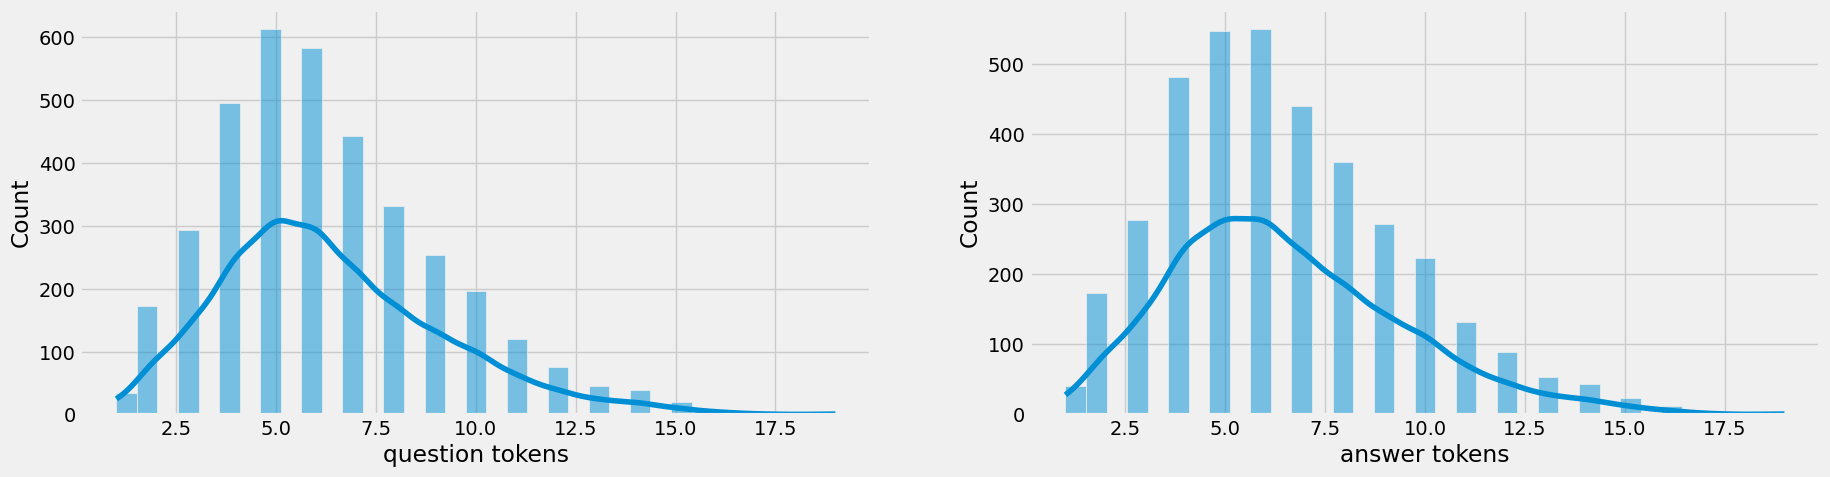

In [50]:
df['question tokens']=df['question'].apply(lambda x:len(x.split()))
df['answer tokens']=df['answer'].apply(lambda x:len(x.split()))
plt.style.use('fivethirtyeight')
fig,ax=plt.subplots(nrows=1,ncols=2,figsize=(20,5))
sns.set_palette('Set2')
sns.histplot(x=df['question tokens'],data=df,kde=True,ax=ax[0])
sns.histplot(x=df['answer tokens'],data=df,kde=True,ax=ax[1])
plt.show()

# Text Cleaning

In [56]:
def clean_text(text):
    text = text.lower().replace('-', ' ')
    # put spaces around punctuation and digits; apostrophes stay inside words (i'm, don't)
    text = re.sub(r'([.,?!$&/:;*"\d])', r' \1 ', text)
    return re.sub(r'\s+', ' ', text).strip()
 
answers = df['answer'].apply(clean_text)
df['encoder_inputs']  = df['question'].apply(clean_text)
df['decoder_inputs']  = '<start> ' + answers      # starts with <start>
df['decoder_targets'] = answers + ' <end>'        # same words, shifted, ends with <end>
 
max_sequence_length = int(max(
    df[c].str.split().str.len().max()
    for c in ['encoder_inputs', 'decoder_inputs', 'decoder_targets']
))
print('Max sequence length:', max_sequence_length)

df.head(20)

Max sequence length: 28


,question,answer,question tokens,answer tokens,encoder_inputs,decoder_inputs,decoder_targets
0,"hi, how are you doing?",i'm fine. how about yourself?,5,5,"hi , how are you doing ?",<start> i'm fine . how about yourself ?,i'm fine . how about yourself ? <end>
1,i'm fine. how about yourself?,i'm pretty good. thanks for asking.,5,6,i'm fine . how about yourself ?,<start> i'm pretty good . thanks for asking .,i'm pretty good . thanks for asking . <end>
2,i'm pretty good. thanks for asking.,no problem. so how have you been?,6,7,i'm pretty good . thanks for asking .,<start> no problem . so how have you been ?,no problem . so how have you been ? <end>
3,no problem. so how have you been?,i've been great. what about you?,7,6,no problem . so how have you been ?,<start> i've been great . what about you ?,i've been great . what about you ? <end>
4,i've been great. what about you?,i've been good. i'm in school right now.,6,8,i've been great . what about you ?,<start> i've been good . i'm in school right n...,i've been good . i'm in school right now . <end>
5,i've been good. i'm in school right now.,what school do you go to?,8,6,i've been good . i'm in school right now .,<start> what school do you go to ?,what school do you go to ? <end>
6,what school do you go to?,i go to pcc.,6,4,what school do you go to ?,<start> i go to pcc .,i go to pcc . <end>
7,i go to pcc.,do you like it there?,4,5,i go to pcc .,<start> do you like it there ?,do you like it there ? <end>
8,do you like it there?,it's okay. it's a really big campus.,5,7,do you like it there ?,<start> it's okay . it's a really big campus .,it's okay . it's a really big campus . <end>
9,it's okay. it's a really big campus.,good luck with school.,7,4,it's okay . it's a really big campus .,<start> good luck with school .,good luck with school . <end>


# Tokenization

In [12]:
params = dict(vocab_limit=5000, learning_rate=1e-3, batch_size=64,
              lstm_cells=256, embedding_dim=256, buffer_size=10000, dropout=0.3)
 
vectorize_layer = TextVectorization(
    max_tokens=params['vocab_limit'],
    standardize=None,                 # text is already cleaned
    split='whitespace',
    output_mode='int',
    output_sequence_length=max_sequence_length,
)
vectorize_layer.adapt(
    pd.concat([df['encoder_inputs'], df['decoder_inputs'], df['decoder_targets']]).tolist()
)
vocab = vectorize_layer.get_vocabulary()
vocab_size = len(vocab)
start_id, end_id = vocab.index('<start>'), vocab.index('<end>')
print('Vocab size:', vocab_size)
 
x  = vectorize_layer(df['encoder_inputs'].tolist())
yd = vectorize_layer(df['decoder_inputs'].tolist())
y  = vectorize_layer(df['decoder_targets'].tolist())

Vocab size: 2490


# Build Model

In [13]:
n_val = int(0.1 * len(x))
 
train_data = (
    tf.data.Dataset.from_tensor_slices((x[:-n_val], yd[:-n_val], y[:-n_val]))
    .cache()
    .shuffle(params['buffer_size'])           # reshuffles each epoch, train only
    .batch(params['batch_size'])
    .prefetch(tf.data.AUTOTUNE)
)
val_data = (
    tf.data.Dataset.from_tensor_slices((x[-n_val:], yd[-n_val:], y[-n_val:]))
    .batch(params['batch_size'])
    .prefetch(tf.data.AUTOTUNE)
)
 
sample = next(iter(train_data))
print('Encoder input:', sample[0].shape, '| Decoder input:', sample[1].shape,
      '| Target:', sample[2].shape)
print('Decoder input :', sample[1][0][:10].numpy())   # starts with <start>
print('Decoder target:', sample[2][0][:10].numpy())   # same words shifted left

Encoder input: (64, 28) | Decoder input: (64, 28) | Target: (64, 28)
Decoder input : [  3   7 101  72   9 476  16  12   2   0]
Decoder target: [  7 101  72   9 476  16  12   2   4   0]


#  Build Encoder

In [29]:
class Encoder(tf.keras.layers.Layer):
    def __init__(self, units, embedding_dim, vocab_size, dropout=0.3, **kwargs):
        super().__init__(**kwargs)
        self.embedding = Embedding(vocab_size, embedding_dim, mask_zero=True,
                                   name='encoder_embedding')
        self.norm = LayerNormalization()
        self.drop = Dropout(dropout)
        self.lstm = LSTM(units, return_state=True, name='encoder_lstm')
 
    def call(self, encoder_inputs, training=None):
        x = self.embedding(encoder_inputs)
        x = self.norm(x)
        x = self.drop(x, training=training)
        _, state_h, state_c = self.lstm(x)
        return state_h, state_c               # no self.inputs / self.outputs here



# Build Decoder

In [44]:
class Decoder(tf.keras.layers.Layer):
    def __init__(self, units, embedding_dim, vocab_size, dropout=0.3, **kwargs):
        super().__init__(**kwargs)
        self.embedding = Embedding(vocab_size, embedding_dim, mask_zero=True,
                                   name='decoder_embedding')
        self.norm_in  = LayerNormalization()
        self.norm_out = LayerNormalization()   # separate weights from norm_in
        self.drop_in  = Dropout(dropout)
        self.drop_out = Dropout(dropout)
        self.lstm = LSTM(units, return_sequences=True, return_state=True,
                         name='decoder_lstm')
        self.fc = Dense(vocab_size, activation='softmax', name='decoder_dense')
 
    def call(self, decoder_inputs, encoder_states, training=None):
        x = self.embedding(decoder_inputs)
        x = self.norm_in(x)
        x = self.drop_in(x, training=training)
        x, _, _ = self.lstm(x, initial_state=list(encoder_states))
        x = self.norm_out(x)
        x = self.drop_out(x, training=training)
        return self.fc(x)

# Build Training model

In [18]:
class ChatBotTrainer(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        # reduction='none' -> per-token loss, so padding can really be masked out
        self.loss_object = tf.keras.losses.SparseCategoricalCrossentropy(reduction='none')
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')
        self.acc_tracker  = tf.keras.metrics.Mean(name='accuracy')
 
    def masked_loss(self, y_true, y_pred):
        mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
        loss = self.loss_object(y_true, y_pred) * mask
        return tf.reduce_sum(loss) / tf.maximum(tf.reduce_sum(mask), 1.0)
 
    def masked_accuracy(self, y_true, y_pred):
        pred = tf.argmax(y_pred, axis=-1, output_type=y_true.dtype)
        mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
        correct = tf.cast(tf.equal(y_true, pred), tf.float32) * mask
        return tf.reduce_sum(correct) / tf.maximum(tf.reduce_sum(mask), 1.0)
 
    def call(self, inputs, training=None):
        encoder_inputs, decoder_inputs = inputs
        states = self.encoder(encoder_inputs, training=training)
        return self.decoder(decoder_inputs, states, training=training)
 
    @property
    def metrics(self):
        # Keras resets these every epoch, so logs are epoch averages (not the last batch)
        return [self.loss_tracker, self.acc_tracker]
 
    def train_step(self, batch):
        encoder_inputs, decoder_inputs, y_true = batch
        with tf.GradientTape() as tape:
            y_pred = self((encoder_inputs, decoder_inputs), training=True)
            loss = self.masked_loss(y_true, y_pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(self.masked_accuracy(y_true, y_pred))
        return {m.name: m.result() for m in self.metrics}
 
    def test_step(self, batch):
        encoder_inputs, decoder_inputs, y_true = batch
        y_pred = self((encoder_inputs, decoder_inputs), training=False)   # dropout OFF
        loss = self.masked_loss(y_true, y_pred)
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(self.masked_accuracy(y_true, y_pred))
        return {m.name: m.result() for m in self.metrics}
 
 
encoder = Encoder(params['lstm_cells'], params['embedding_dim'], vocab_size,
                  dropout=params['dropout'], name='encoder')
decoder = Decoder(params['lstm_cells'], params['embedding_dim'], vocab_size,
                  dropout=params['dropout'], name='decoder')
model = ChatBotTrainer(encoder, decoder, name='chatbot_trainer')
 
model.compile(optimizer=tf.keras.optimizers.Adam(params['learning_rate'], clipnorm=1.0))
model((sample[0], sample[1]))        # call once so all weights are built
model.summary()

Model: "chatbot_trainer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Encoder)               │ ?                      │     1,163,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Decoder)               │ ?                      │     1,803,706 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,966,970 (11.32 MB)

 Trainable params: 2,966,970 (11.32 MB)

 Non-trainable params: 0 (0.00 B)

# Train Model

In [45]:
history = model.fit(
    train_data,
    epochs=100,
    validation_data=val_data,
    callbacks=[
        tf.keras.callbacks.TensorBoard(log_dir='logs'),
        tf.keras.callbacks.ModelCheckpoint(
            'ckpt.weights.h5', monitor='val_loss',
            save_weights_only=True, save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=6, restore_best_weights=True,
        ),
    ],
)

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.1832 - loss: 6.0042
Epoch 1: val_loss improved from None to 4.96253, saving model to ckpt.weights.h5

Epoch 1: finished saving model to ckpt.weights.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 32s 508ms/step - accuracy: 0.2320 - loss: 5.2594 - val_accuracy: 0.2502 - val_loss: 4.9625
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.2954 - loss: 4.2653
Epoch 2: val_loss improved from 4.96253 to 4.66022, saving model to ckpt.weights.h5

Epoch 2: finished saving model to ckpt.weights.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 502ms/step - accuracy: 0.3059 - loss: 4.1659 - val_accuracy: 0.2790 - val_loss: 4.6602
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.3440 - loss: 3.6563
Epoch 3: val_loss improved from 4.66022 to 4.59839, saving model to ckpt.weights.h5

Epoch 3: finished saving model to ckpt.weights.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 26s 486ms/step - accuracy: 0.3459 - loss: 3.6429 - val_accuracy: 0.2880 - 

# Visual Metircs of the training

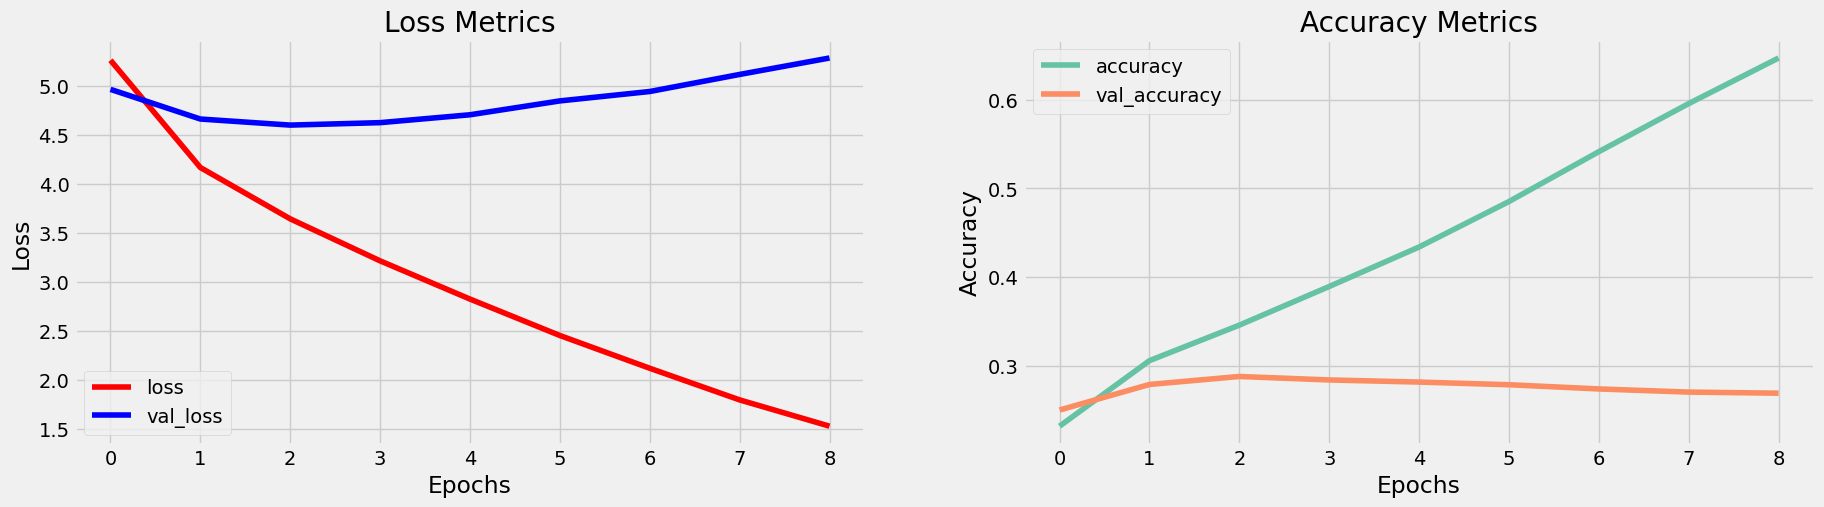

In [46]:
fig,ax=plt.subplots(nrows=1,ncols=2,figsize=(20,5))
ax[0].plot(history.history['loss'],label='loss',c='red')
ax[0].plot(history.history['val_loss'],label='val_loss',c = 'blue')
ax[0].set_xlabel('Epochs')
ax[1].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[1].set_ylabel('Accuracy')
ax[0].set_title('Loss Metrics')
ax[1].set_title('Accuracy Metrics')
ax[1].plot(history.history['accuracy'],label='accuracy')
ax[1].plot(history.history['val_accuracy'],label='val_accuracy')
ax[0].legend()
ax[1].legend()
plt.show()

In [49]:
def chat(text, max_len=max_sequence_length):
    enc = vectorize_layer([clean_text(text)])
    states = encoder(enc, training=False)
    ids = [start_id]
    for _ in range(max_len - 1):
        dec_in = tf.constant([ids], dtype=tf.int64)
        probs = decoder(dec_in, states, training=False)
        next_id = int(tf.argmax(probs[0, -1]))
        if next_id == end_id:
            break
        ids.append(next_id)
    return ' '.join(vocab[i] for i in ids[1:])
 
print(chat('hi, how are you doing?'))

i'm not .


# Save Model

In [61]:
model.load_weights('ckpt.weights.h5')              # best epoch by val_loss
model.save_weights('chatbot_trainer.weights.h5')
 
config = {
    'vocab': vocab,
    'vocab_size': vocab_size,
    'max_sequence_length': max_sequence_length,
    'lstm_cells': params['lstm_cells'],
    'embedding_dim': params['embedding_dim'],
    'start_id': start_id,
    'end_id': end_id,
}
with open('chatbot_config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f)

# Chat Inference

In [62]:
units = params['lstm_cells']
 
enc_in = tf.keras.Input(shape=(max_sequence_length,), dtype='int64', name='question_ids')
x = encoder.embedding(enc_in)
x = encoder.norm(x)
x = encoder.drop(x)                                # dropout is inactive at inference
_, enc_h, enc_c = encoder.lstm(x)
encoder_model = tf.keras.Model(enc_in, [enc_h, enc_c], name='encoder_model')
 
dec_token  = tf.keras.Input(shape=(1,), dtype='int64', name='decoder_token')
dec_state_h = tf.keras.Input(shape=(units,), name='state_h')
dec_state_c = tf.keras.Input(shape=(units,), name='state_c')
x = decoder.embedding(dec_token)
x = decoder.norm_in(x)
x = decoder.drop_in(x)
x, dec_h, dec_c = decoder.lstm(x, initial_state=[dec_state_h, dec_state_c])
x = decoder.norm_out(x)
x = decoder.drop_out(x)
dec_probs = decoder.fc(x)
decoder_model = tf.keras.Model([dec_token, dec_state_h, dec_state_c],
                               [dec_probs, dec_h, dec_c], name='decoder_model')
 
encoder_model.summary()
decoder_model.summary()
 
encoder_model.save('encoder_model.keras')
decoder_model.save('decoder_model.keras')

Model: "encoder_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ question_ids        │ (None, 28)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 28, 256)   │    637,440 │ question_ids[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 28, 256)   │        512 │ encoder_embeddin… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 28, 256)   │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 28)        │          0 │ question_ids[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    525,312 │ dropout_3[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,163,264 (4.44 MB)

 Trainable params: 1,163,264 (4.44 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_token       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 1, 256)    │    637,440 │ decoder_token[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 1, 256)    │        512 │ decoder_embeddin… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1, 256)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_h             │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_c             │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 1, 256),  │    525,312 │ dropout_4[0][0],  │
│                     │ (None, 256),      │            │ state_h[0][0],    │
│                     │ (None, 256)]      │            │ state_c[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 1, 256)    │        512 │ decoder_lstm[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 1, 256)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 1, 2490)   │    639,930 │ dropout_5[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,803,706 (6.88 MB)

 Trainable params: 1,803,706 (6.88 MB)

 Non-trainable params: 0 (0.00 B)

# The chatbot

In [66]:
word2id = {w: i for i, w in enumerate(vocab)}
UNK_ID = word2id['[UNK]']
 
 
def encode_text(text):
    """Same as TextVectorization: split on spaces, unknown -> [UNK], cut/pad to length."""
    ids = [word2id.get(w, UNK_ID) for w in clean_text(text).split()][:max_sequence_length]
    ids += [0] * (max_sequence_length - len(ids))
    return np.array([ids], dtype='int64')
 
 
def tidy(reply):
    """'i'm fine . how about you ?' -> "i'm fine. how about you?" """
    return re.sub(r'\s+([.,?!:;])', r'\1', reply).strip()
 
 
def generate_reply(text, temperature=0.0, top_k=5, max_len=max_sequence_length):
    """temperature=0 -> greedy (most likely word). temperature>0 -> sample from the
    top_k words, which gives more varied (but riskier) replies."""
    if not text.strip():
        return 'Say something!'
    h, c = encoder_model.predict(encode_text(text), verbose=0)
    token, words = start_id, []
    for _ in range(max_len):
        probs, h, c = decoder_model.predict(
            [np.array([[token]], dtype='int64'), h, c], verbose=0)
        p = probs[0, -1].astype('float64')
        p[[0, UNK_ID, start_id]] = 0.0             # never emit padding, [UNK] or <start>
        if temperature <= 0:
            token = int(np.argmax(p))
        else:
            top = np.argsort(p)[-top_k:]
            q = p[top] ** (1.0 / temperature)
            token = int(np.random.choice(top, p=q / q.sum()))
        if token == end_id:
            break
        words.append(vocab[token])
    return tidy(' '.join(words))
 
 
def conversation(prompts, **kwargs):
    """Print a scripted conversation."""
    for prompt in prompts:
        print(f'You: {prompt}')
        print(f'Bot: {generate_reply(prompt, **kwargs)}\n')
 
 
def chat_loop(**kwargs):
    """Interactive chat. Type 'quit' to stop."""
    print("Chatbot ready. Type 'quit' to exit.\n")
    while True:
        user = input('You: ')
        if user.strip().lower() in {'quit', 'exit', 'bye'}:
            print('Bot: bye!')
            break
        print('Bot:', generate_reply(user, **kwargs), '\n')
 
 
conversation([
    'hi, how are you doing?',
    'what school do you go to?',
    'do you like it there?',
    'thank you very much.',
])
 
chat_loop()

You: hi, how are you doing?
Bot: i'm not.

You: what school do you go to?
Bot: i think i think i think.

You: do you like it there?
Bot: i don't know.

You: thank you very much.
Bot: i think i think that.

Chatbot ready. Type 'quit' to exit.



You:  Hello


Bot: i think that. 



You:  hi, how are you ?


Bot: no, i think i think. 



...

Bot: how about you? 



You:  good


Bot: i think that. 



You:  bye


Bot: bye!


In [67]:
encoder_model = tf.keras.models.load_model('encoder_model.keras')
decoder_model = tf.keras.models.load_model('decoder_model.keras')
with open('chatbot_config.json', encoding='utf-8') as f:
    cfg = json.load(f)
 
vocab = cfg['vocab']
max_sequence_length = cfg['max_sequence_length']
start_id, end_id = cfg['start_id'], cfg['end_id']
word2id = {w: i for i, w in enumerate(vocab)}
UNK_ID = word2id['[UNK]']
 
 
def clean_text(text):                      # must match the training-time cleaning
    text = text.lower().replace('-', ' ')
    text = re.sub(r'([.,?!$&/:;*"\d])', r' \1 ', text)
    return re.sub(r'\s+', ' ', text).strip()
 
 
def encode_text(text):
    ids = [word2id.get(w, UNK_ID) for w in clean_text(text).split()][:max_sequence_length]
    ids += [0] * (max_sequence_length - len(ids))
    return np.array([ids], dtype='int64')
 
 
def tidy(reply):
    return re.sub(r'\s+([.,?!:;])', r'\1', reply).strip()
 
 
def generate_reply(text, temperature=0.0, top_k=5, max_len=max_sequence_length):
    if not text.strip():
        return 'Say something!'
    h, c = encoder_model.predict(encode_text(text), verbose=0)
    token, words = start_id, []
    for _ in range(max_len):
        probs, h, c = decoder_model.predict(
            [np.array([[token]], dtype='int64'), h, c], verbose=0)
        p = probs[0, -1].astype('float64')
        p[[0, UNK_ID, start_id]] = 0.0
        if temperature <= 0:
            token = int(np.argmax(p))
        else:
            top = np.argsort(p)[-top_k:]
            q = p[top] ** (1.0 / temperature)
            token = int(np.random.choice(top, p=q / q.sum()))
        if token == end_id:
            break
        words.append(vocab[token])
    return tidy(' '.join(words))
 
 
if __name__ == '__main__':
    print("Chatbot ready. Type 'quit' to exit.\n")
    while True:
        user = input('You: ')
        if user.strip().lower() in {'quit', 'exit', 'bye'}:
            print('Bot: bye!')
            break
        print('Bot:', generate_reply(user), '\n')
 

Chatbot ready. Type 'quit' to exit.



You:  hello


Bot: i think that. 



You:  yes


Bot: what do you want to do? 



...

Bot: i think that. 



You:  you are the best


Bot: i think i think that. 



You:  bye


Bot: bye!
